In [ ]:
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import apriori, association_rules
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
import os

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Define the path to the dataset
data_path = '/content/drive/My Drive/datasets/samman/cad_mirnas/data/mirnas_data.xlsx'

# Verify if the file exists
if os.path.exists(data_path):
    print("File found. Proceeding with loading and processing.")

    # Load the dataset
    df = pd.read_excel(data_path)

    # Preprocessing: Expand miRNA column into individual columns
    df['miRNA'] = df['miRNA'].str.split(',')
    df_expanded = df.explode('miRNA').reset_index(drop=True)

    # Create a binary matrix for miRNAs
    binary_matrix = pd.crosstab(df_expanded['GENE'], df_expanded['miRNA'])

    # Convert the matrix to binary (0s and 1s)
    binary_matrix = binary_matrix.applymap(lambda x: 1 if x > 0 else 0)

    # Ensure the binary matrix aligns with the original dataframe
    aligned_genes = binary_matrix.index.intersection(df['GENE'])
    binary_matrix = binary_matrix.loc[aligned_genes]

    # Determine optimal number of clusters using the elbow method
    distortions = []
    K = range(1, 10)
    for k in K:
        kmeans = KMeans(n_clusters=k, random_state=42)
        kmeans.fit(binary_matrix)
        distortions.append(kmeans.inertia_)

    # Plot the elbow method graph
    plt.figure(figsize=(10, 6))
    plt.plot(K, distortions, 'bo-')
    plt.xlabel('Number of Clusters')
    plt.ylabel('Distortion')
    plt.title('Elbow Method for Optimal Number of Clusters')
    plt.show()

    # Apply k-means clustering with k=3
    kmeans = KMeans(n_clusters=3, random_state=42)
    clusters = kmeans.fit_predict(binary_matrix)

    # Add the cluster assignments to the original dataframe
    df['Cluster'] = df['GENE'].map(dict(zip(aligned_genes, clusters)))

    # Rename clusters 0 -> 1, 1 -> 2, 2 -> 3
    df['Cluster'] = df['Cluster'] + 1

    # Clustering validation metrics
    silhouette_avg = silhouette_score(binary_matrix, clusters)
    db_index = davies_bouldin_score(binary_matrix, clusters)
    print(f'Silhouette Score: {silhouette_avg}')
    print(f'Davies-Bouldin Index: {db_index}')

    # Perform PCA to reduce dimensions
    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(binary_matrix)

    # Add PCA results to the dataframe
    df_pca = pd.DataFrame(pca_result, columns=['PCA1', 'PCA2'], index=binary_matrix.index)
    df_pca['Cluster'] = df['Cluster']

    # Plot the PCA results
    plt.figure(figsize=(12, 8))
    sns.scatterplot(x='PCA1', y='PCA2', hue='Cluster', palette='Set1', data=df_pca)
    plt.title('PCA of Gene Clusters (k=3)')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.legend(title='Cluster')
    plt.show()

    # Association Rule Mining
    frequent_itemsets = apriori(binary_matrix, min_support=0.03, use_colnames=True)
    print("Frequent Itemsets:")
    print(frequent_itemsets)
    rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)
    print("Association Rules:")
    print(rules)

    # Filter association rules by lift
    high_lift_rules = rules[rules['lift'] > 1.0]

    # Visualization
    # Network graph of miRNA associations within each cluster
    for cluster_num in range(1, 4):
        cluster_genes = df[df['Cluster'] == cluster_num]['GENE'].tolist()
        cluster_miRNAs = binary_matrix.loc[cluster_genes]
        B = nx.Graph()

        # Add cluster nodes
        for gene in cluster_genes:
            B.add_node(gene, bipartite=0, type='gene')

        # Add miRNA nodes and edges
        for miRNA in cluster_miRNAs.columns:
            miRNA_targets = cluster_miRNAs[cluster_miRNAs[miRNA] > 0].index.tolist()
            B.add_node(miRNA, bipartite=1, type='miRNA')
            for gene in miRNA_targets:
                B.add_edge(miRNA, gene)

        plt.figure(figsize=(10, 8))
        pos = nx.spring_layout(B, seed=42)
        nx.draw(B, pos, with_labels=True, node_size=1000, font_size=10, font_color='black', font_weight='bold', node_color='skyblue', edge_color='gray', width=1.5)
        plt.title(f'Network Graph for Cluster {cluster_num}')
        plt.show()

    # Bar chart showing gene distribution across clusters
    plt.figure(figsize=(8, 6))
    sns.countplot(data=df, x='Cluster')
    plt.title('Gene Distribution Across Clusters')
    plt.xlabel('Cluster')
    plt.ylabel('Count')
    plt.show()

    # Bipartite graph mapping miRNA associations to gene clusters
    B = nx.Graph()
    for gene in df['GENE']:
        miRNAs = binary_matrix.columns[binary_matrix.loc[gene] == 1]
        cluster = df[df['GENE'] == gene]['Cluster'].values[0]
        B.add_node(gene, bipartite=0, type='gene', cluster=cluster)
        for miRNA in miRNAs:
            B.add_node(miRNA, bipartite=1, type='miRNA')
            B.add_edge(gene, miRNA)

    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(B, seed=42)
    nx.draw(B, pos, with_labels=True, node_size=1500, font_size=10, font_color='black', font_weight='bold', node_color='skyblue', edge_color='gray', width=1.5)
    plt.title('Bipartite Graph of miRNA-Gene Associations')
    plt.show()

else:
    print(f"File not found at {data_path}. Please check the file path and try again.")


Mounted at /content/drive
File found. Proceeding with loading and processing.


/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:8

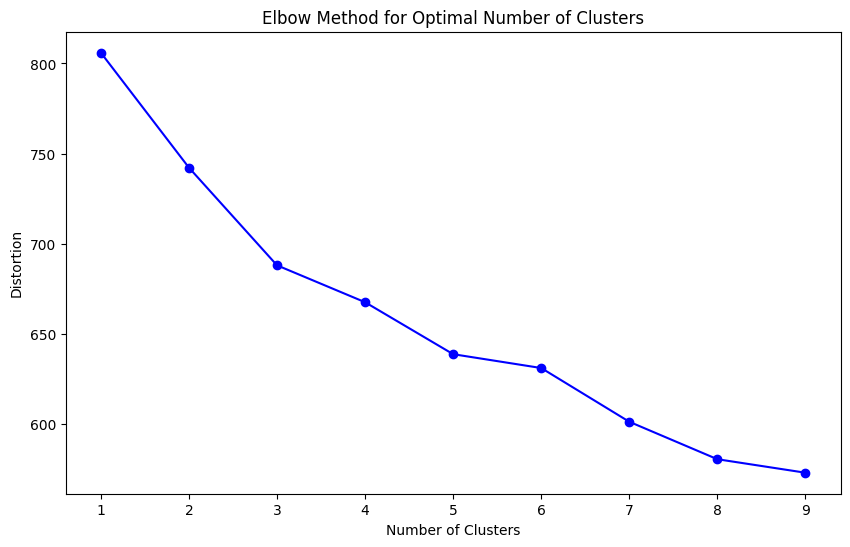

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Silhouette Score: 0.2693672704554422
Davies-Bouldin Index: 1.4566379668853637
Frequent Itemsets:
      support                                           itemsets
0    0.054852                                         (let-7-5p)
1    0.033755                                         (miR-1-3p)
2    0.037975                                     (miR-101-3p.2)
3    0.054852                                       (miR-106-5p)
4    0.037975                                     (miR-124-3p.1)
..        ...                                                ...
109  0.050633    (miR-497-5p, miR-424-5p, miR-16-5p, miR-195-5p)
110  0.037975      (miR-93-5p, miR-20-5p, miR-519-3p, miR-17-5p)
111  0.033755     (miR-92-3p, miR-363-3p, miR-367-3p, miR-32-5p)
112  0.037975  (miR-17-5p, miR-106-5p, miR-93-5p, miR-20-5p, ...
113  0.046414  (miR-497-5p, miR-424-5p, miR-16-5p, miR-15-5p,...

[114 rows x 2 columns]


/usr/local/lib/python3.10/dist-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


Association Rules:
      antecedents                                      consequents  \
0      (let-7-5p)                                      (miR-98-5p)   
1     (miR-98-5p)                                       (let-7-5p)   
2      (miR-1-3p)                                        (miR-206)   
3       (miR-206)                                       (miR-1-3p)   
4     (miR-17-5p)                                     (miR-106-5p)   
..            ...                                              ...   
419  (miR-497-5p)   (miR-15-5p, miR-424-5p, miR-16-5p, miR-195-5p)   
420  (miR-424-5p)   (miR-15-5p, miR-497-5p, miR-16-5p, miR-195-5p)   
421   (miR-16-5p)  (miR-424-5p, miR-15-5p, miR-497-5p, miR-195-5p)   
422   (miR-15-5p)  (miR-424-5p, miR-497-5p, miR-16-5p, miR-195-5p)   
423  (miR-195-5p)   (miR-424-5p, miR-15-5p, miR-497-5p, miR-16-5p)   

     antecedent support  consequent support   support  confidence       lift  \
0              0.054852            0.042194  0.042194    0.7

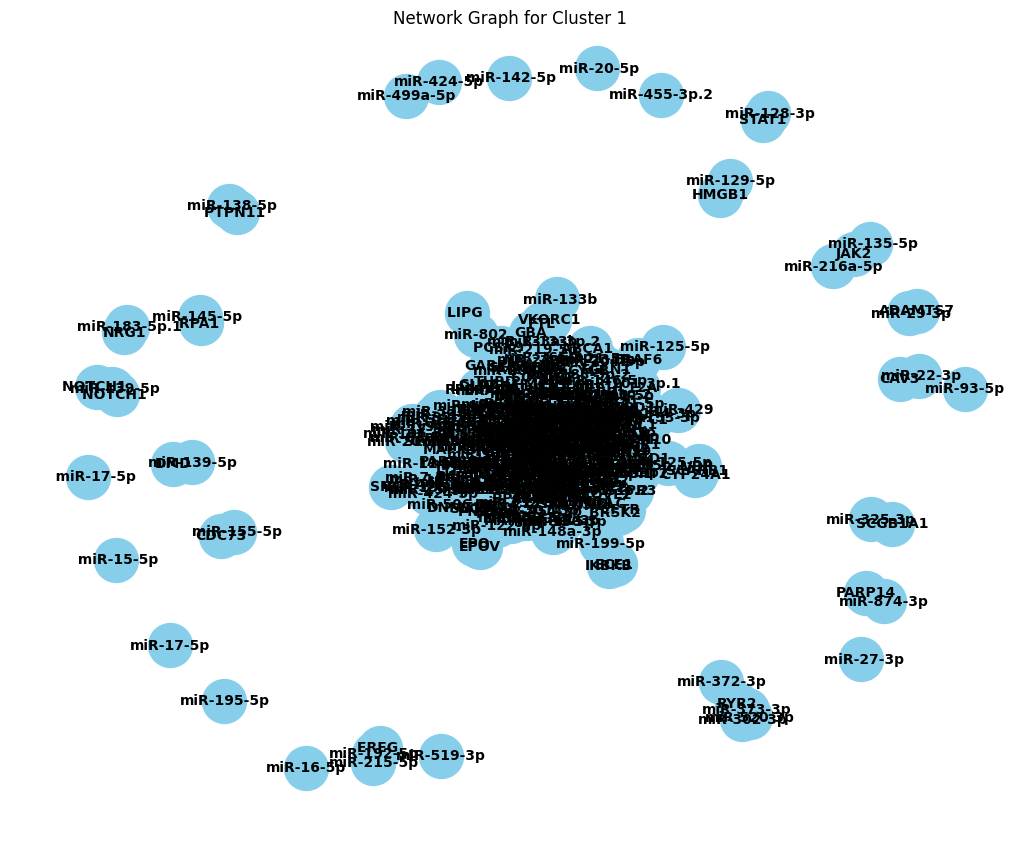

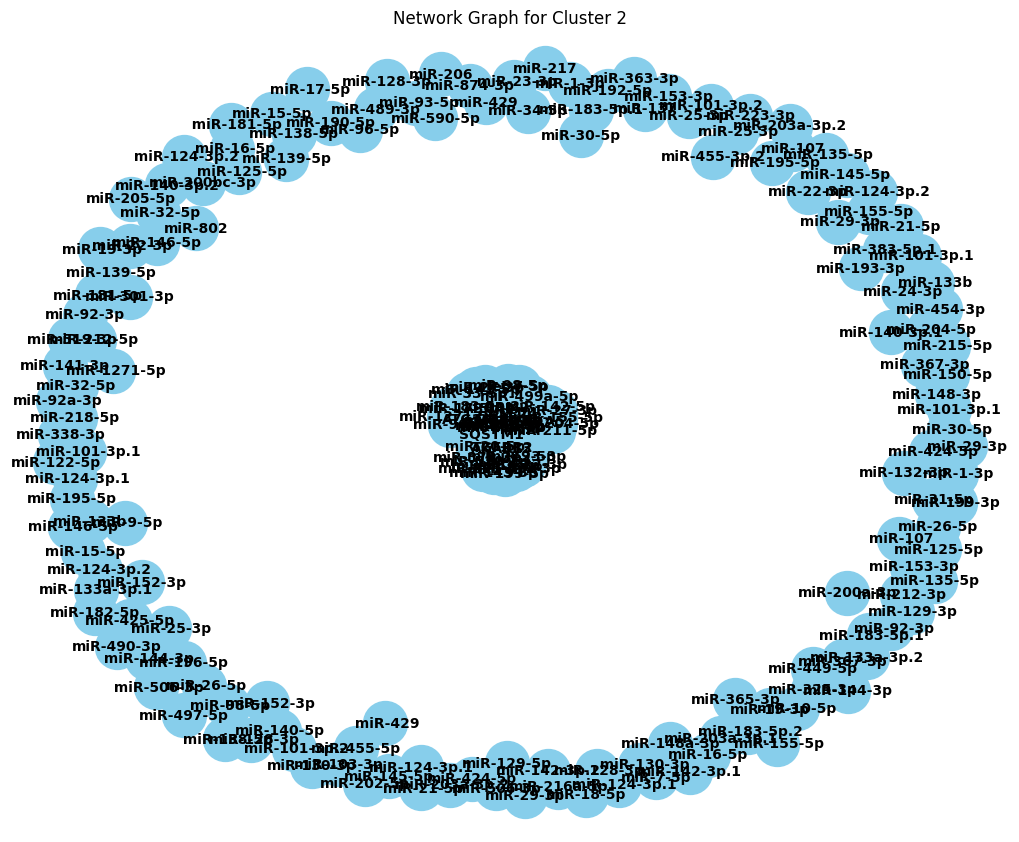

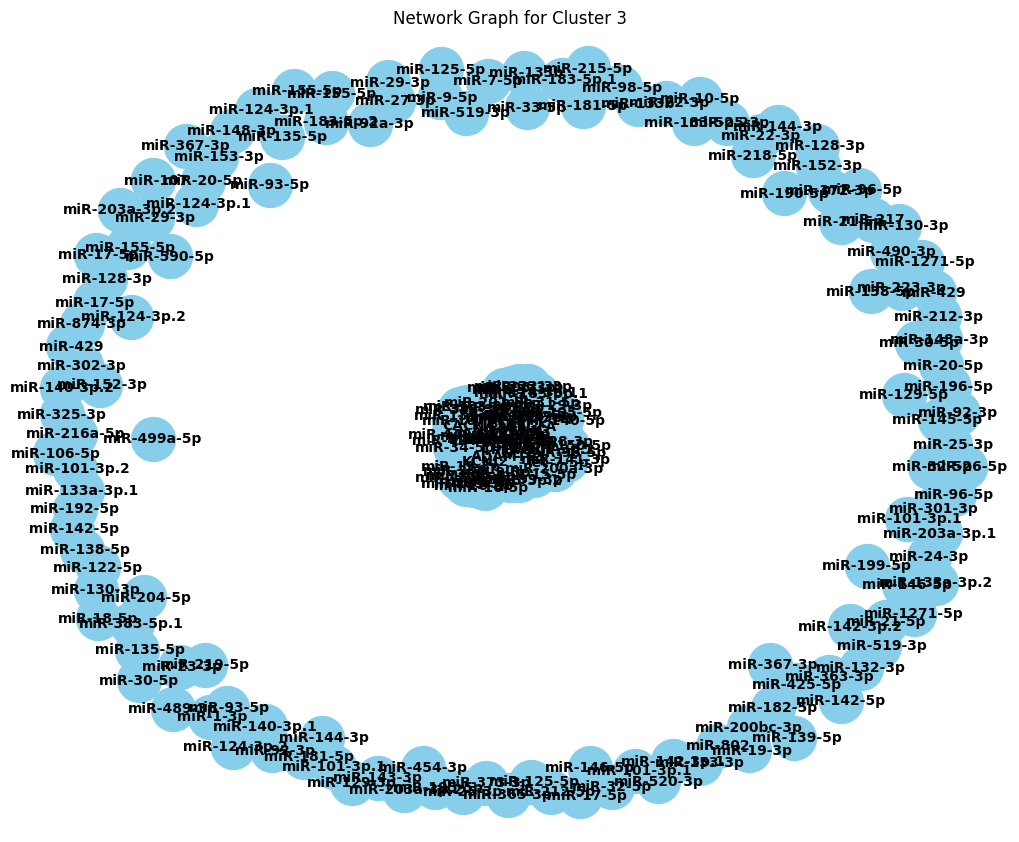

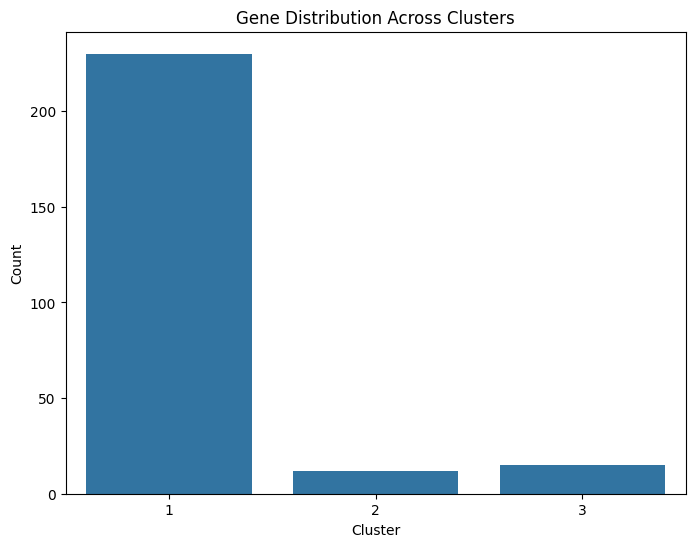

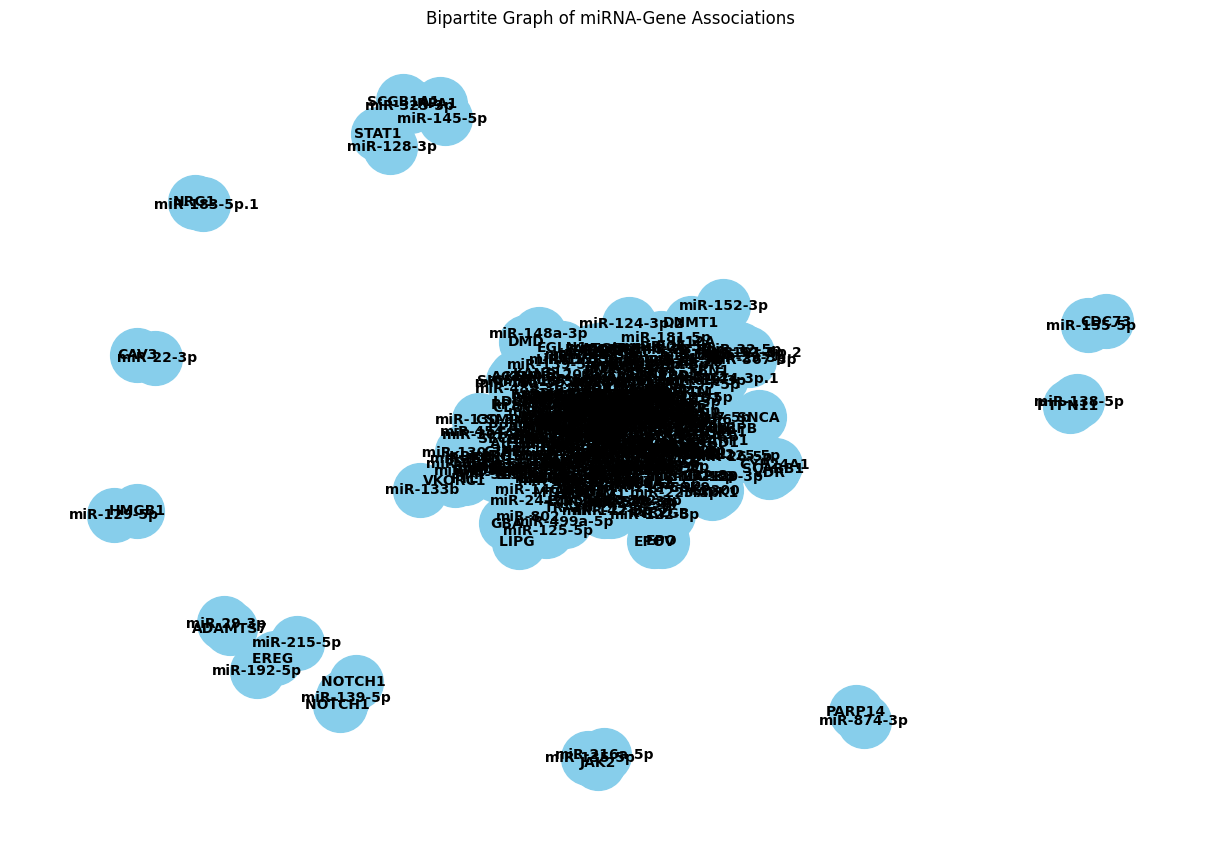

In [1]:
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import apriori, association_rules
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import os

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Define the path to the dataset
data_path = '/content/drive/My Drive/datasets/samman/cad_mirnas/data/mirnas_data.xlsx'

# Verify if the file exists
if os.path.exists(data_path):
    print("File found. Proceeding with loading and processing.")

    # Load the dataset
    df = pd.read_excel(data_path)

    # Preprocessing: Expand miRNA column into individual columns
    df['miRNA'] = df['miRNA'].str.split(',')
    df_expanded = df.explode('miRNA').reset_index(drop=True)

    # Create a binary matrix for miRNAs
    binary_matrix = pd.crosstab(df_expanded['GENE'], df_expanded['miRNA'])

    # Convert the matrix to binary (0s and 1s)
    binary_matrix = binary_matrix.applymap(lambda x: 1 if x > 0 else 0)

    # Ensure the binary matrix aligns with the original dataframe
    aligned_genes = binary_matrix.index.intersection(df['GENE'])
    binary_matrix = binary_matrix.loc[aligned_genes]

    # Determine optimal number of clusters using the elbow method
    distortions = []
    K = range(1, 10)
    for k in K:
        kmeans = KMeans(n_clusters=k, random_state=42)
        kmeans.fit(binary_matrix)
        distortions.append(kmeans.inertia_)

    # Plot the elbow method graph
    plt.figure(figsize=(10, 6))
    plt.plot(K, distortions, 'bo-')
    plt.xlabel('Number of Clusters')
    plt.ylabel('Distortion')
    plt.title('Elbow Method for Optimal Number of Clusters')
    plt.show()

    # Apply k-means clustering with k=3
    kmeans = KMeans(n_clusters=3, random_state=42)
    clusters = kmeans.fit_predict(binary_matrix)

    # Add the cluster assignments to the original dataframe
    df['Cluster'] = df['GENE'].map(dict(zip(aligned_genes, clusters)))

    # Rename clusters 0 -> 1, 1 -> 2, 2 -> 3
    df['Cluster'] = df['Cluster'] + 1

    # Clustering validation metrics
    silhouette_avg = silhouette_score(binary_matrix, clusters)
    db_index = davies_bouldin_score(binary_matrix, clusters)
    print(f'Silhouette Score: {silhouette_avg}')
    print(f'Davies-Bouldin Index: {db_index}')

    # Association Rule Mining
    frequent_itemsets = apriori(binary_matrix, min_support=0.03, use_colnames=True)
    print("Frequent Itemsets:")
    print(frequent_itemsets)
    rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)
    print("Association Rules:")
    print(rules)

    # Filter association rules by lift
    high_lift_rules = rules[rules['lift'] > 1.0]

    # Visualization
    # Network graph of miRNA associations within each cluster
    for cluster_num in range(1, 4):
        cluster_genes = df[df['Cluster'] == cluster_num]['GENE'].tolist()
        cluster_miRNAs = binary_matrix.loc[cluster_genes]
        B = nx.Graph()

        # Add cluster nodes
        for gene in cluster_genes:
            B.add_node(gene, bipartite=0, type='gene')

        # Add miRNA nodes and edges
        for miRNA in cluster_miRNAs.columns:
            miRNA_targets = cluster_miRNAs[cluster_miRNAs[miRNA] > 0].index.tolist()
            B.add_node(miRNA, bipartite=1, type='miRNA')
            for gene in miRNA_targets:
                B.add_edge(miRNA, gene)

        plt.figure(figsize=(10, 8))
        pos = nx.spring_layout(B, seed=42)
        nx.draw(B, pos, with_labels=True, node_size=1000, font_size=10, font_color='black', font_weight='bold', node_color='skyblue', edge_color='gray', width=1.5)
        plt.title(f'Network Graph for Cluster {cluster_num}')
        plt.show()

    # Bar chart showing gene distribution across clusters
    plt.figure(figsize=(8, 6))
    sns.countplot(data=df, x='Cluster')
    plt.title('Gene Distribution Across Clusters')
    plt.xlabel('Cluster')
    plt.ylabel('Count')
    plt.show()

    # Bipartite graph mapping miRNA associations to gene clusters
    B = nx.Graph()
    for gene in df['GENE']:
        miRNAs = binary_matrix.columns[binary_matrix.loc[gene] == 1]
        cluster = df[df['GENE'] == gene]['Cluster'].values[0]
        B.add_node(gene, bipartite=0, type='gene', cluster=cluster)
        for miRNA in miRNAs:
            B.add_node(miRNA, bipartite=1, type='miRNA')
            B.add_edge(gene, miRNA)

    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(B, seed=42)
    nx.draw(B, pos, with_labels=True, node_size=1500, font_size=10, font_color='black', font_weight='bold', node_color='skyblue', edge_color='gray', width=1.5)
    plt.title('Bipartite Graph of miRNA-Gene Associations')
    plt.show()

else:
    print(f"File not found at {data_path}. Please check the file path and try again.")
